# Análise Descritiva — Biblioteca (Sprint 1)

**Persona / cliente:** a coordenadora de uma biblioteca comunitária, que precisa decidir
o que comprar, quais prazos de empréstimo praticar e como reduzir atrasos.

**Objetivos de negócio → perguntas**
1. Quais gêneros têm mais saída? (orientar compras) → *gráfico de barras*
2. Como a demanda e os atrasos variam ao longo do tempo? (planejar equipe/acervo) → *série temporal*
3. Quanto tempo os itens ficam emprestados e o prazo atual é adequado? → *histograma*
4. Livros maiores demoram mais para voltar? (calibrar prazo por tamanho) → *dispersão + regressão*

> Os dados (`emprestimos.csv`) são **simulados** (`gerar_dados.py`). Na Sprint 2, substitua
> por dados reais exportados da API mantendo as mesmas colunas.

In [1]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

os.makedirs("graficos", exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 5), "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("emprestimos.csv", parse_dates=["data_emprestimo"])
df["atrasou"] = df["dias_atraso"] > 0
df["mes"] = df["data_emprestimo"].dt.to_period("M")
df.head()

,id_emprestimo,id_leitor,tipo,genero,paginas,data_emprestimo,prazo_dias,dias_emprestimo,dias_atraso,multa,atrasou,mes
0,1,55,Livro,Ficção Científica,281,2025-01-02,14,7,0,0.0,False,2025-01
1,2,42,Livro,Técnico,399,2025-01-05,14,14,0,0.0,False,2025-01
2,3,26,Livro,Infantil,412,2025-01-09,14,14,0,0.0,False,2025-01
3,4,17,Livro,Infantil,315,2025-01-11,14,10,0,0.0,False,2025-01
4,5,4,Revista,Infantil,90,2025-01-12,7,7,0,0.0,False,2025-01


## 1. Métricas de negócio (KPIs)

In [2]:
total = len(df)
taxa_atraso = df["atrasou"].mean() * 100
atrasados = df[df["atrasou"]]

kpis = {
    "Total de empréstimos": total,
    "Taxa de atraso (%)": round(taxa_atraso, 1),
    "Duração média do empréstimo (dias)": round(df["dias_emprestimo"].mean(), 1),
    "Duração mediana (dias)": df["dias_emprestimo"].median(),
    "Desvio padrão da duração (dias)": round(df["dias_emprestimo"].std(), 1),
    "Atraso médio entre os atrasados (dias)": round(atrasados["dias_atraso"].mean(), 1),
    "Multa total arrecadada (R$)": round(df["multa"].sum(), 2),
    "Multa média por atraso (R$)": round(atrasados["multa"].mean(), 2),
    "Leitores distintos": df["id_leitor"].nunique(),
}
pd.Series(kpis, name="valor").to_frame()

,valor
Total de empréstimos,600.00
Taxa de atraso (%),29.50
Duração média do empréstimo (dias),11.00
Duração mediana (dias),11.00
Desvio padrão da duração (dias),4.80
Atraso médio entre os atrasados (dias),2.90
Multa total arrecadada (R$),724.50
Multa média por atraso (R$),4.09
Leitores distintos,119.00


**Taxa de atraso por tipo de item** — compara Livro (prazo 14 dias) e Revista (prazo 7 dias).

In [3]:
por_tipo = df.groupby("tipo").agg(
    emprestimos=("id_emprestimo", "count"),
    taxa_atraso_pct=("atrasou", lambda s: round(s.mean() * 100, 1)),
    duracao_media=("dias_emprestimo", lambda s: round(s.mean(), 1)),
)
por_tipo

,emprestimos,taxa_atraso_pct,duracao_media
tipo,,,
Livro,476,31.9,12.5
Revista,124,20.2,5.0


## 2. Gêneros mais emprestados (barras)

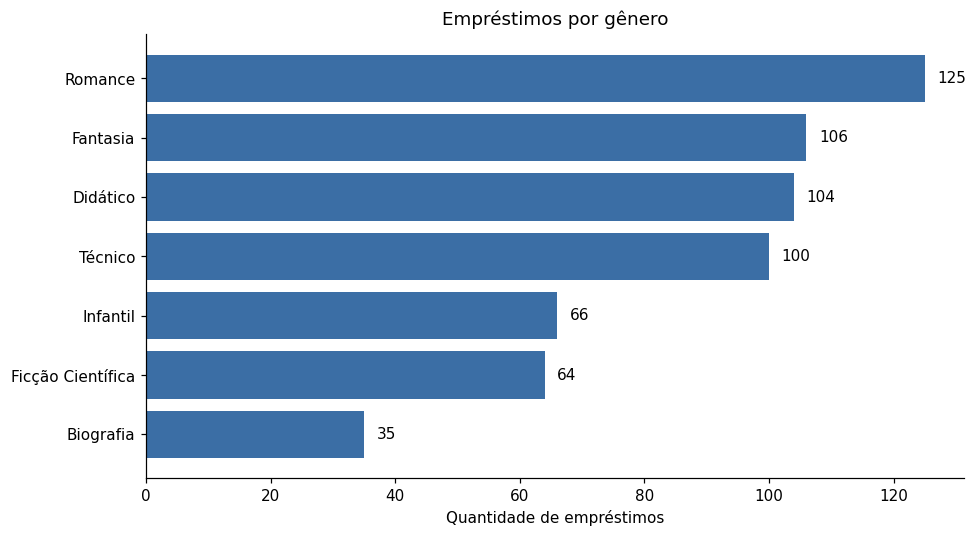

genero
Romance              125
Fantasia             106
Didático             104
Técnico              100
Infantil              66
Ficção Científica     64
Biografia             35
Name: count, dtype: int64

In [4]:
ranking = df["genero"].value_counts().sort_values()
fig, ax = plt.subplots()
ax.barh(ranking.index, ranking.values, color="#3b6ea5")
for y, v in enumerate(ranking.values):
    ax.text(v + 2, y, str(v), va="center")
ax.set_title("Empréstimos por gênero")
ax.set_xlabel("Quantidade de empréstimos")
fig.tight_layout()
fig.savefig("graficos/01_generos_barras.png", dpi=150)
ranking.sort_values(ascending=False)

## 3. Evolução mensal de empréstimos e da taxa de atraso (série temporal)

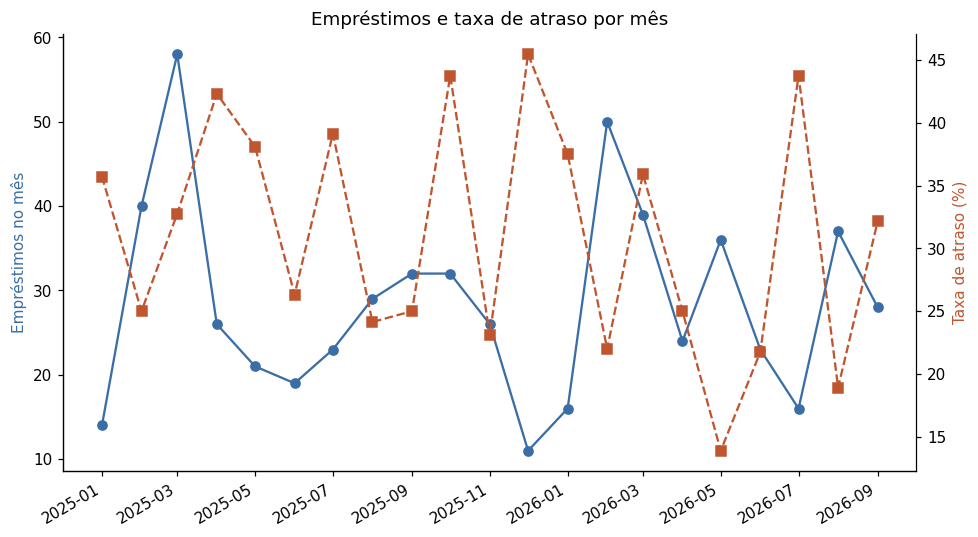

,emprestimos,taxa_atraso
mes,,
2026-04-01,24,0.25
2026-05-01,36,0.14
2026-06-01,23,0.22
2026-07-01,16,0.44
2026-08-01,37,0.19
2026-09-01,28,0.32


In [5]:
mensal = df.groupby("mes").agg(
    emprestimos=("id_emprestimo", "count"),
    taxa_atraso=("atrasou", "mean"),
)
mensal.index = mensal.index.to_timestamp()

fig, ax1 = plt.subplots()
ax1.plot(mensal.index, mensal["emprestimos"], marker="o", color="#3b6ea5", label="Empréstimos")
ax1.set_ylabel("Empréstimos no mês", color="#3b6ea5")
ax2 = ax1.twinx()
ax2.spines["right"].set_visible(True)
ax2.plot(mensal.index, mensal["taxa_atraso"] * 100, marker="s", linestyle="--", color="#c0562f", label="Taxa de atraso")
ax2.set_ylabel("Taxa de atraso (%)", color="#c0562f")
ax1.set_title("Empréstimos e taxa de atraso por mês")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("graficos/02_serie_temporal.png", dpi=150)
mensal.round(2).tail(6)

## 4. Distribuição da duração dos empréstimos (histograma)
As linhas verticais mostram os prazos praticados: quem passa delas está em atraso.

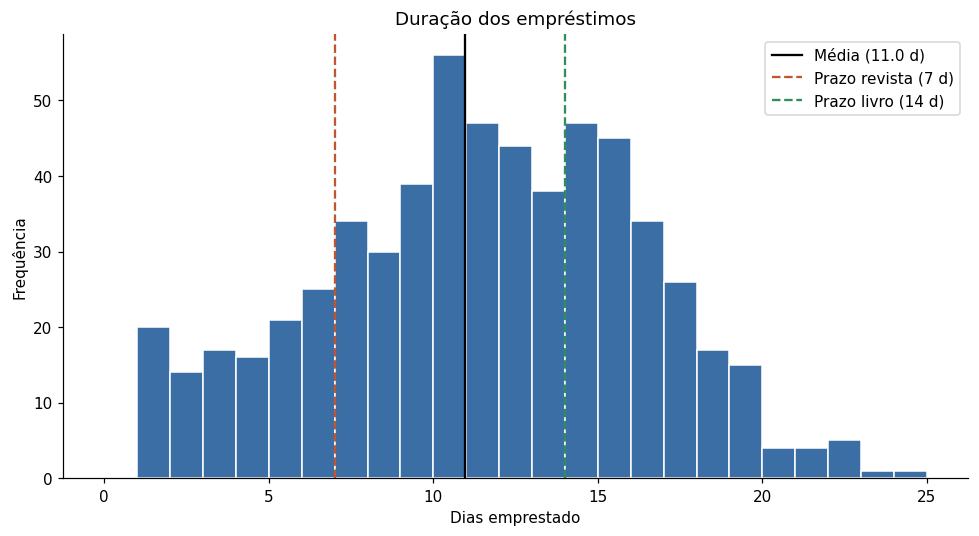

count    600.00
mean      10.96
std        4.83
min        1.00
25%        8.00
50%       11.00
75%       15.00
max       24.00
Name: dias_emprestimo, dtype: float64

In [6]:
fig, ax = plt.subplots()
ax.hist(df["dias_emprestimo"], bins=range(0, int(df["dias_emprestimo"].max()) + 2), color="#3b6ea5", edgecolor="white")
ax.axvline(df["dias_emprestimo"].mean(), color="black", linestyle="-", label=f"Média ({df['dias_emprestimo'].mean():.1f} d)")
ax.axvline(7, color="#c0562f", linestyle="--", label="Prazo revista (7 d)")
ax.axvline(14, color="#2f8f5b", linestyle="--", label="Prazo livro (14 d)")
ax.set_title("Duração dos empréstimos")
ax.set_xlabel("Dias emprestado")
ax.set_ylabel("Frequência")
ax.legend()
fig.tight_layout()
fig.savefig("graficos/03_histograma_duracao.png", dpi=150)
df["dias_emprestimo"].describe().round(2)

## 5. Tamanho do livro × tempo de empréstimo (dispersão + regressão linear)

Coeficiente: +2.2 dias a cada 100 páginas | R² = 0.39
Em média, livros acima de ~357 páginas passam do prazo de 14 dias.


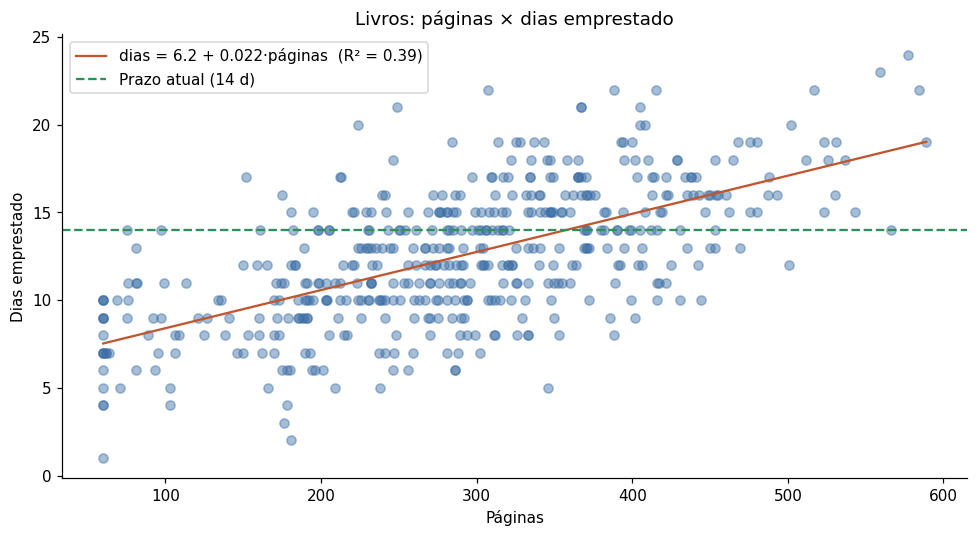

In [7]:
livros = df[df["tipo"] == "Livro"]
reg = stats.linregress(livros["paginas"], livros["dias_emprestimo"])

fig, ax = plt.subplots()
ax.scatter(livros["paginas"], livros["dias_emprestimo"], alpha=0.45, color="#3b6ea5")
xs = pd.Series([livros["paginas"].min(), livros["paginas"].max()])
ax.plot(xs, reg.intercept + reg.slope * xs, color="#c0562f",
        label=f"dias = {reg.intercept:.1f} + {reg.slope:.3f}·páginas  (R² = {reg.rvalue**2:.2f})")
ax.axhline(14, color="#2f8f5b", linestyle="--", label="Prazo atual (14 d)")
ax.set_title("Livros: páginas × dias emprestado")
ax.set_xlabel("Páginas")
ax.set_ylabel("Dias emprestado")
ax.legend()
fig.tight_layout()
fig.savefig("graficos/04_dispersao_regressao.png", dpi=150)

paginas_no_prazo = (14 - reg.intercept) / reg.slope
print(f"Coeficiente: +{reg.slope * 100:.1f} dias a cada 100 páginas | R² = {reg.rvalue**2:.2f}")
print(f"Em média, livros acima de ~{paginas_no_prazo:.0f} páginas passam do prazo de 14 dias.")

## 6. Conclusões para o cliente
> Baseadas nos dados **simulados** atuais; refaça os números quando houver dados reais.

- **Compras:** Romance (125), Fantasia (106), Didático (104) e Técnico (100) concentram a maior parte dos empréstimos; Biografia é o gênero com menos saída (35). Priorizar a renovação do acervo nos quatro primeiros.
- **Atrasos:** 29,5% dos empréstimos passam do prazo, com atraso médio de 2,9 dias entre os atrasados. Livros atrasam mais (31,9%) do que revistas (20,2%).
- **Sazonalidade:** a demanda sobe no início de cada semestre (fev/mar e ago/set), com o mês de pico variando conforme o ano. Reforçar atendimento e acervo nesses períodos.
- **Prazo por tamanho:** a regressão indica +2,2 dias de empréstimo a cada 100 páginas (R² = 0,39). Livros acima de ~357 páginas tendem a ultrapassar os 14 dias. Sugestão: avaliar prazo de 21 dias para livros grandes e, assim, reduzir multas e atrasos.